# Polar Kerr Effect of a Magnetic Multilayer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/06-light/03-polar_kerr_multilayer.ipynb)

In this example the static polar magneto-optical Kerr effect (MOKE) of a metallic multilayer is calculated for visible light and compared to the measurements of {cite:t}`anadon2025`.
The sample consists of a Co/Ni multilayer with perpendicular magnetic anisotropy, which is covered by a Cu layer of variable thickness $t_\mathrm{Cu}$:

    sapphire // Ta(3) / Cu(5) / [Ni(0.7) / Co(0.2)]4 / Cu(t_Cu) / Al(3)

where all thicknesses are given in nm.
The Kerr rotation $\theta_k$ and ellipticity $\varepsilon_k$ are probed at normal incidence at a wavelength of 785 nm either from the Cu side or through the transparent sapphire substrate from the ferromagnetic (FM) side.
The comparison of both sides is the basis of the analysis of the magneto-optical signals of ultrafast spin accumulations in {cite:t}`anadon2025`.

Here, the Kerr angles at saturation are calculated with the multilayer formalisms of the {py:mod}`scattering <udkm1Dsim.simulations.scattering>` package, see the [example of the multilayer formalisms](#example_multilayer_formalisms) and the [magneto-optics example](#example_magneto_optics).

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Optical Constants

The refractive indices of all layers at 785 nm are taken from the [refractiveindex.info](https://refractiveindex.info) database {cite:p}`polyanskiy2024`, see the [dielectric example](#example_dielectric), which requires the optional package `refractiveindex`, e.g. installed by `pip install udkm1Dsim[refractiveindex]`.
As in {cite:t}`anadon2025`, the optical constants of Cu, Ni, and Co are taken from {cite:t}`johnson1972` and {cite:t}`johnson1974`, the ones of Ta from {cite:t}`ordal1988`, and the ordinary refractive index of sapphire from {cite:t}`malitson1972`.
The Al capping layer is assumed to be completely passivated, so that it is described by sapphire as well.

:::{admonition} References {cite}`johnson1972,johnson1974,ordal1988,malitson1972`
:class: seealso
P. B. Johnson and R. W. Christy, _Optical Constants of the Noble Metals_, [Phys. Rev. B 6, 4370 (1972)](https://doi.org/10.1103/PhysRevB.6.4370)

P. B. Johnson and R. W. Christy, _Optical constants of transition metals: Ti, V, Cr, Mn, Fe, Co, Ni, and Pd_, [Phys. Rev. B 9, 5056 (1974)](https://doi.org/10.1103/PhysRevB.9.5056)

M. A. Ordal et al., _Optical properties of Al, Fe, Ti, Ta, W, and Mo at submillimeter wavelengths_, [Appl. Opt. 27, 1203 (1988)](https://doi.org/10.1364/AO.27.001203)

I. H. Malitson and M. J. Dodge, _Refractive index and birefringence of synthetic sapphire_, J. Opt. Soc. Am. 62, 1336 (1972)
:::

In [2]:
n_Cu = ud.Dispersion.from_refractiveindex("main", "Cu", "Johnson")
n_Ni = ud.Dispersion.from_refractiveindex("main", "Ni", "Johnson")
n_Co = ud.Dispersion.from_refractiveindex("main", "Co", "Johnson")
n_Ta = ud.Dispersion.from_refractiveindex("main", "Ta", "Ordal")
n_sapphire = ud.Dispersion.from_refractiveindex("main", "Al2O3", "Malitson-o")

/tmp/ipykernel_1411428/3981094371.py:5: UserWarning: The page RefractiveIndexMaterial(shelf='main', book='Al2O3', page='Malitson-o') of refractiveindex.info has no extinction coefficient, so that kappa = 0 is assumed.
  n_sapphire = ud.Dispersion.from_refractiveindex("main", "Al2O3", "Malitson-o")


The magneto-optical response of the Co/Ni multilayer is given by the complex Voigt constant $Q$ in the gyrotropic part $\varepsilon^m = Q \varepsilon_{xx}$ of the dielectric tensor, see the [dielectric example](#example_dielectric).
Here, the value $Q_\mathrm{Co/Ni} = 0.012 - 0.016i$, which was fitted by {cite:t}`anadon2025` to the measurements, is used for both the Ni and the Co layers.

:::{admonition} Reference {cite}`anadon2025`
:class: seealso
A. Anadón et al., _Large spin accumulation signals in ultrafast magneto-optical experiments_, [Phys. Rev. B 112, 104437 (2025)](https://doi.org/10.1103/5qnm-zgjt)
:::

In [3]:
Q = ud.Dispersion.from_array(None, 0.012 - 0.016j, kind="voigt")

## Structure

Refer to the [structure example](#example_structure) for more details.

All layers are homogeneous {py:class}`Layer <udkm1Dsim.structures.layers.Layer>`s, where the magnetization of the Ni and Co layers points along the surface normal $z$.

In [4]:
layer_Ta = ud.Layer(
    "Ta",
    "Ta buffer",
    structural=ud.StructuralParameters(thickness=3 * u.nm, density=16650 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=n_Ta),
)
layer_Cu_buffer = ud.Layer(
    "Cu_buffer",
    "Cu buffer",
    structural=ud.StructuralParameters(thickness=5 * u.nm, density=8960 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=n_Cu),
)
layer_Ni = ud.Layer(
    "Ni",
    "Ni",
    structural=ud.StructuralParameters(thickness=0.7 * u.nm, density=8908 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=ud.Dielectric(eps0=n_Ni, eps_mag=Q)),
    magnetic=ud.MagneticParameters(magnetization=(0, 0, 1)),
)
layer_Co = ud.Layer(
    "Co",
    "Co",
    structural=ud.StructuralParameters(thickness=0.2 * u.nm, density=8900 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=ud.Dielectric(eps0=n_Co, eps_mag=Q)),
    magnetic=ud.MagneticParameters(magnetization=(0, 0, 1)),
)
layer_Cu = ud.Layer(
    "Cu",
    "Cu",
    structural=ud.StructuralParameters(thickness=20 * u.nm, density=8960 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=n_Cu),
)
layer_cap = ud.Layer(
    "AlOx",
    "passivated Al cap",
    structural=ud.StructuralParameters(thickness=3 * u.nm, density=3987 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=n_sapphire),
)
sapphire = ud.Layer(
    "sapphire",
    "sapphire",
    structural=ud.StructuralParameters(thickness=0 * u.nm, density=3987 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=n_sapphire),
)

For the probe from the Cu side, the light is incident from vacuum on the Al cap and the sapphire forms the semi-infinite substrate.
For the probe from the FM side, the light is incident from the sapphire as superstrate on the Ta buffer and leaves the sample into vacuum.
The second structure, hence, contains the same layers in reversed order.

In [5]:
S_Cu = ud.Structure("probed from the Cu side")
S_Cu.add_sub_structure(layer_cap, 1)
S_Cu.add_sub_structure(layer_Cu, 1)
for i in range(4):
    S_Cu.add_sub_structure(layer_Co, 1)
    S_Cu.add_sub_structure(layer_Ni, 1)
S_Cu.add_sub_structure(layer_Cu_buffer, 1)
S_Cu.add_sub_structure(layer_Ta, 1)
S_Cu.add_substrate(sapphire)

S_FM = ud.Structure("probed from the FM side")
S_FM.add_superstrate(sapphire)
S_FM.add_sub_structure(layer_Ta, 1)
S_FM.add_sub_structure(layer_Cu_buffer, 1)
for i in range(4):
    S_FM.add_sub_structure(layer_Ni, 1)
    S_FM.add_sub_structure(layer_Co, 1)
S_FM.add_sub_structure(layer_Cu, 1)
S_FM.add_sub_structure(layer_cap, 1)
S_FM.add_substrate(ud.Vacuum(thickness=0 * u.nm))

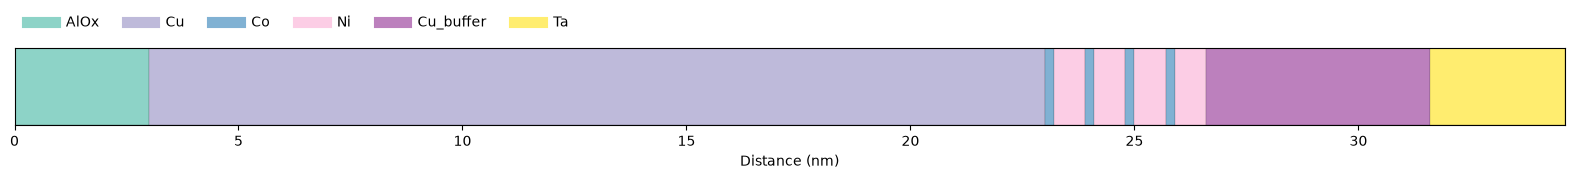

In [6]:
S_Cu.visualize()

## Initialize the Multilayer Simulations

The magnetization of the multilayer is weak, so that the formalism of {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` to first order in the magnetization is appropriate.
For each side, a simulation at normal incidence, i.e. at $\theta = 90°$, is set up.

In [7]:
simulations = {}
for side, S in [("Cu side", S_Cu), ("FM side", S_FM)]:
    sim = ud.Elzo(S, True)
    sim.save_data = False
    sim.disp_messages = False
    sim.wl = np.r_[785] * u.nm
    sim.theta = np.r_[90] * u.deg
    simulations[side] = sim

simulations["FM side"]

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized
incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized


parameter,value
force recalc,True
cache directory,./
display messages,False
save data,False
progress bar,True
energy,1.579 eV
wavelength,785 nm
wavenumber,0.008004 1/nm
theta,[90] deg
q_z,[0.01601] 1/nm


## Kerr Rotation and Ellipticity

The Kerr rotation $\theta_k$ and ellipticity $\varepsilon_k$ follow from the complex Jones matrix of the reflection, see {py:meth}`calc_kerr_angles <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_kerr_angles>`, for every thickness $t_\mathrm{Cu}$ of the top Cu layer.

In [8]:
thicknesses = np.r_[5:150.5:0.5] * u.nm
kerr = {}
for side, sim in simulations.items():
    kerr[side] = np.zeros([len(thicknesses), 2])
    for i, thickness in enumerate(thicknesses):
        layer_Cu.thickness = thickness
        R, R_phi, T, T_phi = sim.homogeneous_jones_matrices()
        rotation, ellipticity = sim.calc_kerr_angles(R)
        kerr[side][i, :] = [rotation.m_as("urad").item(), ellipticity.m_as("urad").item()]

The exact eigenmodes of {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` confirm the first-order formalism of {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>`, also for the light incident from the sapphire.

In [9]:
layer_Cu.thickness = 40 * u.nm
for side, S in [("Cu side", S_Cu), ("FM side", S_FM)]:
    bs = ud.BerremanStepanov(S, True, save_data=False, disp_messages=False)
    bs.wl = np.r_[785] * u.nm
    bs.theta = np.r_[90] * u.deg
    R_exact = bs.homogeneous_jones_matrices()[0]
    R_first_order = simulations[side].homogeneous_jones_matrices()[0]
    exact = [angle.m_as("urad").item() for angle in bs.calc_kerr_angles(R_exact)]
    first_order = [angle.m_as("urad").item() for angle in bs.calc_kerr_angles(R_first_order)]
    print(f"{side}: Elzo {np.round(first_order, 2)} µrad")
    print(f"{side}: BerremanStepanov {np.round(exact, 2)} µrad")

Cu side: Elzo [ 67.54 -74.11] µrad
Cu side: BerremanStepanov [ 67.54 -74.11] µrad
FM side: Elzo [  213.22 -1218.48] µrad
FM side: BerremanStepanov [  213.22 -1218.48] µrad


## Comparison to the Measurements

The measured Kerr rotation and ellipticity at saturation of Fig. 1(e) and 1(f) of {cite:t}`anadon2025` are provided as dataset {cite:p}`anadon2025data` under the license [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

When probed from the Cu side, the Kerr angles decay with the thickness of the Cu layer as $\exp(-4 \pi \kappa_\mathrm{Cu} t_\mathrm{Cu} / \lambda)$ by the absorption in the Cu layer on the way to the Co/Ni multilayer and back, which is shown for comparison.

:::{admonition} Reference {cite}`anadon2025data`
:class: seealso
A. Anadón, _Dataset for Large spin accumulation signals in ultrafast magneto-optical experiments in Physical Review B_, [Zenodo (2025)](https://doi.org/10.5281/zenodo.17142927)
:::

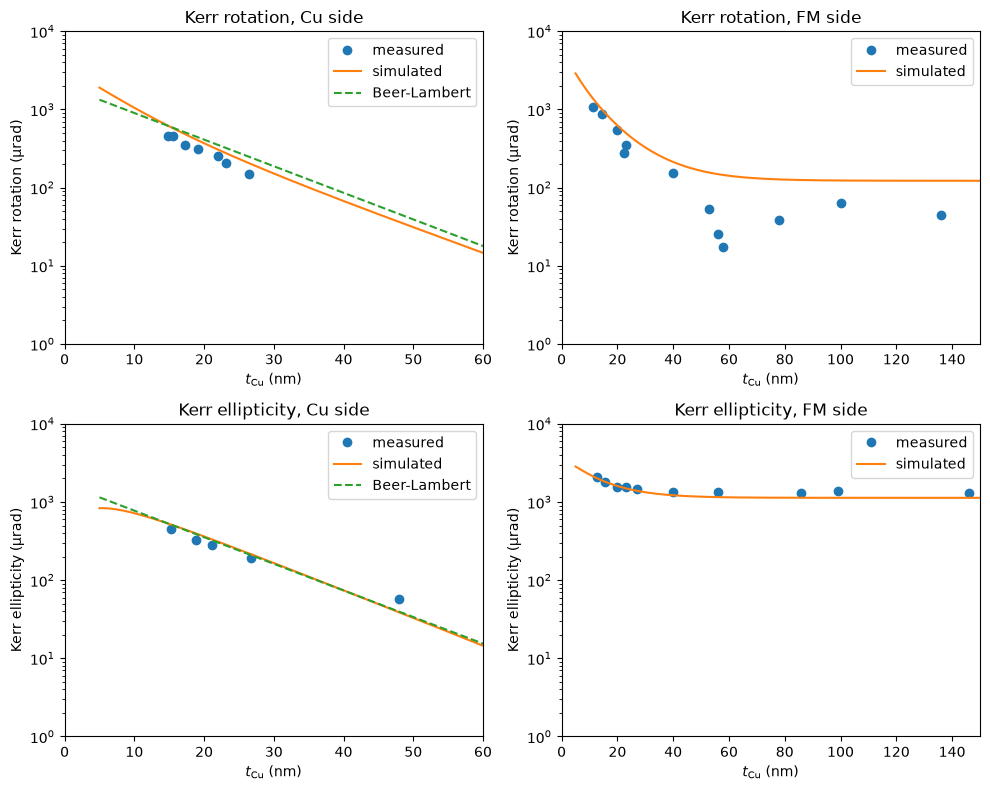

In [10]:
data = np.loadtxt("Anadon2025_Fig1ef.txt")

kappa_Cu = np.imag(np.sqrt(n_Cu.eps(785 * u.nm)))[0]
beer_lambert = np.exp(-4 * np.pi * kappa_Cu * thicknesses / (785 * u.nm)).m_as("")
i_ref = np.argmin(np.abs(thicknesses - 15 * u.nm))

plt.figure(figsize=[10, 8])
for col, side in enumerate(["Cu side", "FM side"]):
    for row, quantity in enumerate(["rotation", "ellipticity"]):
        plt.subplot(2, 2, 2 * row + col + 1)
        select = (data[:, 2] == col) & (data[:, 3] == row)
        plt.semilogy(data[select, 0], data[select, 1], "o", label="measured")
        plt.semilogy(thicknesses, np.abs(kerr[side][:, row]), label="simulated")
        if side == "Cu side":
            plt.semilogy(
                thicknesses,
                np.abs(kerr[side][i_ref, row]) * beer_lambert / beer_lambert[i_ref],
                "--",
                label="Beer-Lambert",
            )
        plt.xlim(0, 60 if side == "Cu side" else 150)
        plt.ylim(1, 1e4)
        plt.xlabel(r"$t_\mathrm{Cu}$ (nm)")
        plt.ylabel(f"Kerr {quantity} (µrad)")
        plt.legend()
        plt.title(f"Kerr {quantity}, {side}")

plt.tight_layout()
plt.show()

When probed from the Cu side, the simulation reproduces the magnitude and the decay of both Kerr angles, which follow the absorption in the Cu layer.
When probed from the FM side, the simulated ellipticity also agrees with the measurement, while the measured rotation drops more strongly with the thickness of the Cu layer and shows a minimum around $t_\mathrm{Cu} \approx 55$ nm, which is not reproduced here.
{cite:t}`anadon2025` attribute the rotation at small $t_\mathrm{Cu}$ to the light, which gains a Faraday rotation in the Co/Ni multilayer and is reflected at the interface of the Cu layer and the cap.
Its interference with the reflection from the other interfaces is very sensitive to the optical constants of the thin metal films, which differ from the bulk values of the database used here.